# 02 · Statistical profile

Milestone week 5: centre, spread, one relationship, one place where a summary misleads,
and what this data does **not** let me conclude.

Input: `data/processed/buurten_story.csv` from notebook 01. The distance calculation lives in
`app/helpers.py`, so the app later uses exactly the same code.



In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "app"))
from helpers import add_distance, load_buurten, weighted_median

ANCHOR = os.environ.get("ANCHOR_CITY", "Utrecht")   # the default city of the story
df = load_buurten(ROOT / "data" / "processed" / "buurten_story.csv")
print(df.shape, "| anchor city:", ANCHOR)

(14729, 35) | anchor city: Utrecht


## 0 · What does CBS say the main measure is?

Before describing a number I want CBS's own definition, not my assumption.

In [2]:
mc = pd.read_csv(ROOT / "data" / "raw" / "MeasureCodes.csv", sep=";", encoding="utf-8", dtype=str)
used = ["M001642", "1014850_2", "A047047", "A047048", "D000025", "ST0001"]
cols = [c for c in ["Identifier", "Title", "Description", "Unit"] if c in mc.columns]
pd.set_option("display.max_colwidth", 400)
mc[mc["Identifier"].isin(used)][cols]

,Identifier,Title,Description,Unit
38,M001642,Gemiddelde WOZ-waarde van woningen,Voor de bepaling van de gemiddelde WOZ-waarde van woningen wordt alleen gebruik gemaakt van BAG-objecten met een woonfunctie waarvoor een WOZ-waarde bekend is en die tussen de 10 duizend en de 5 miljoen euro ligt. \r\n\r\nEr wordt geen gemiddelde WOZ-waarde bepaald voor een regio als:\r\n-\tde woningvoorraad kleiner is dan 20 woningen\r\n-\ter voor minder dan 20 woningen een WOZ-waarde bekend ...,x 1 000 euro
47,1014850_2,Huurwoningen totaal,Peildatum: 1 januari van het desbetreffende jaar.\r\nHet aantal is vermeld als percentage van het totaal aantal woningen en vermeld bij 20 woningen of meer per buurt en wanneer het aandeel woningen met eigendom onbekend 50 procent of minder bedroeg.\r\n,%
48,A047047,In bezit woningcorporatie,"Huurwoningen in eigendom van 'toegelaten instellingen volkshuisvesting'. Het betreft het aantal huurwoningen waarvan is vastgesteld dat de eigenaar een toegelaten instelling is. Het betreft niet het aantal sociale huurwoningen, omdat er alleen is vastgesteld wie de eigenaar is en er niet is gekeken naar de hoogte van de huurprijs.\r\nToegelaten instellingen: woningbouwvereniging, woningstichti...",%
49,A047048,In bezit overige verhuurders,"Een huurwoning in eigendom van onder andere bedrijven, particulieren en institutionele beleggers. Huurwoningen waarvan het eigendom wel kon worden vastgesteld maar de eigenaar niet vallen hier ook onder. \r\nBedrijven: alle instellingen met een bedrijfsmatig karakter zoals bv's en nv's, zelfstandige ondernemers, makelaars en vastgoedhandelsmaatschappijen.\r\nParticulieren: alle natuurlijke per...",%
110,D000025,Afstand tot grote supermarkt,"De gemiddelde afstand van alle inwoners in een gebied tot de dichtstbijzijnde grote supermarkt, berekend over de weg.\r\n\r\nGrote supermarkt:\r\nWinkel met meerdere soorten dagelijkse artikelen en een minimale oppervlakte van 150 m2.\r\n",km
119,ST0001,Mate van stedelijkheid,"Op grond van de omgevingsadressendichtheid is aan iedere buurt, wijk of gemeente een stedelijkheidsklasse toegekend. De volgende klassenindeling is gehanteerd:\r\n1: zeer sterk stedelijk >= 2 500 adressen per km²\r\n2: sterk stedelijk 1 500 - 2 500 adressen per km²\r\n3: matig stedelijk 1 000 - 1 500 adressen per km²\r\n4: weinig stedelijk 500 - 1 000 adressen per km²\r\n5: niet stedelijk < 5...",code


**What is WOZ exactly, which reference date, is it a market price or a tax value?** 

**My reading:** WOZ is the value the municipality puts on a home for tax purposes. It is not
an asking price and definitely not a rent, so in the story I can only say "lower housing
values", never "cheaper to rent". CBS also explains my missing values: rental shares are only
published for neighbourhoods with at least 20 homes, which fits the 11.5% that is missing
as one block. One thing I had wrong: "owned by a housing corporation" is not the same as
social housing, CBS says it only looked at who owns the home, not at the rent. And the
supermarket distance is measured over the road, while my distance to the city is a straight
line, so the two are not the same kind of distance.

## 1 · Centre and spread of the average WOZ value

Measured values only here: the 1,842 neighbourhoods with an estimated value would pull everything
towards their municipality's median.

In [3]:
measured = df[~df["woz_estimated"]]
woz = measured["avg_woz_value_k_eur"]
profile = pd.Series({
    "neighbourhoods (measured)": len(woz),
    "mean (k€)": woz.mean(),
    "median (k€)": woz.median(),
    "std (k€)": woz.std(),
    "Q1 (k€)": woz.quantile(0.25),
    "Q3 (k€)": woz.quantile(0.75),
    "IQR (k€)": woz.quantile(0.75) - woz.quantile(0.25),
    "min (k€)": woz.min(),
    "max (k€)": woz.max(),
    "skew": woz.skew(),
}).round(1)
profile.to_frame("avg WOZ value")

,avg WOZ value
neighbourhoods (measured),12891.0
mean (k€),449.6
median (k€),422.0
std (k€),174.1
Q1 (k€),333.0
Q3 (k€),528.0
IQR (k€),195.0
min (k€),31.0
max (k€),2286.0
skew,2.0


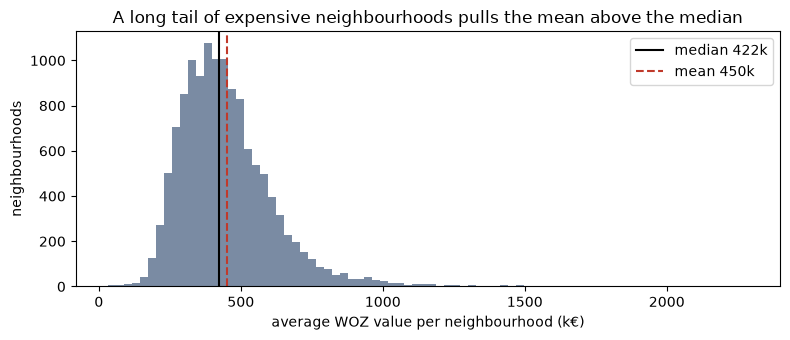

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(woz, bins=80, color="#7a8ba3")
ax.axvline(woz.median(), color="black", lw=1.5, label=f"median {woz.median():.0f}k")
ax.axvline(woz.mean(), color="#c0392b", lw=1.5, ls="--", label=f"mean {woz.mean():.0f}k")
ax.set_xlabel("average WOZ value per neighbourhood (k€)")
ax.set_ylabel("neighbourhoods")
ax.set_title("A long tail of expensive neighbourhoods pulls the mean above the median")
ax.legend()
plt.tight_layout(); plt.show()

**Which centre would I report to a newcomer, and why?**

**My reading:** The mean (450k) sits above the median (422k) because a small number of very
expensive neighbourhoods pull it up (skew 2.0, max 2.3 million). For a newcomer the median is
the more honest "typical" value, so that is the one I will use. The middle half of all
neighbourhoods lies between 333k and 528k, which is a spread of almost 200k, so "the typical
Dutch neighbourhood" already hides a lot of variation.

## 2 · Where a summary misleads: the average of averages

Every row is a neighbourhood, and every neighbourhood counts once, whether it has 15 homes or 3,000.
"The median neighbourhood" is not "the median home". Weighting by `dwelling_count` answers the
question a newcomer actually has: *what does a typical home cost here?*

In [5]:
w = measured["dwelling_count"]
compare = pd.DataFrame({
    "per neighbourhood (each counts once)": [woz.mean(), woz.median()],
    "per home (weighted by dwellings)": [np.average(woz, weights=w), weighted_median(woz, w)],
}, index=["mean (k€)", "median (k€)"]).round(1)
compare

,per neighbourhood (each counts once),per home (weighted by dwellings)
mean (k€),449.6,397.5
median (k€),422.0,374.0


In [6]:
small = measured["dwelling_count"] < measured["dwelling_count"].quantile(0.25)
print(f"smallest quarter of neighbourhoods: {small.mean():.0%} of rows, "
      f"{measured.loc[small, 'dwelling_count'].sum() / w.sum():.1%} of all homes")
print("median WOZ, smallest quarter :", measured.loc[small, "avg_woz_value_k_eur"].median())
print("median WOZ, the rest         :", measured.loc[~small, "avg_woz_value_k_eur"].median())

smallest quarter of neighbourhoods: 25% of rows, 2.5% of all homes
median WOZ, smallest quarter : 515.0
median WOZ, the rest         : 393.0


**How big is the gap, which way does it go, and what kind of neighbourhoods cause it?**

**My reading:** If I count every neighbourhood once, the median is 422k. If I count every home
once, it is 374k, about 48k (13%) lower. The reason is that the smallest quarter of
neighbourhoods holds only 2.5% of all homes but is clearly more expensive (median 515k vs 393k),
probably villages and spread-out rural areas with large houses. A summary per neighbourhood
gives those few homes the same weight as a city district with thousands of homes. For a
newcomer, who is looking for one home and not for a neighbourhood, "the median neighbourhood"
overstates what a typical home is worth. I have to keep this in mind for my own charts too,
because the distance bands below are also per neighbourhood.

## 3 · One relationship: housing value and distance to the city

The core of the story. Distance is straight-line from each neighbourhood to the population-weighted
centre of the anchor city (`app/helpers.py`). I look at medians per 5 km band rather than one
correlation number, because the relationship does not have to be a straight line.

In [7]:
d = add_distance(df, ANCHOR)
near = d[(d["dist_to_city_km"] <= 50) & ~d["woz_estimated"]].copy()
near["band"] = pd.cut(near["dist_to_city_km"], bins=range(0, 55, 5), right=False)

by_band = near.groupby("band", observed=True).agg(
    neighbourhoods=("avg_woz_value_k_eur", "size"),
    median_woz=("avg_woz_value_k_eur", "median"),
    q1=("avg_woz_value_k_eur", lambda s: s.quantile(0.25)),
    q3=("avg_woz_value_k_eur", lambda s: s.quantile(0.75)),
    median_private_rent_pct=("pct_rent_private", "median"),
).round(1)
by_band

,neighbourhoods,median_woz,q1,q3,median_private_rent_pct
band,,,,,
"[0, 5)",103,469.0,420.0,595.5,20.0
"[5, 10)",168,483.5,406.5,611.5,9.0
"[10, 15)",165,578.0,460.0,737.0,11.0
"[15, 20)",208,551.0,416.5,723.0,9.0
"[20, 25)",417,475.0,399.0,627.0,8.0
"[25, 30)",477,497.0,385.0,607.0,10.0
"[30, 35)",673,489.0,394.0,603.0,12.0
"[35, 40)",642,445.5,370.0,528.8,8.0
"[40, 45)",835,421.0,345.0,527.0,9.0


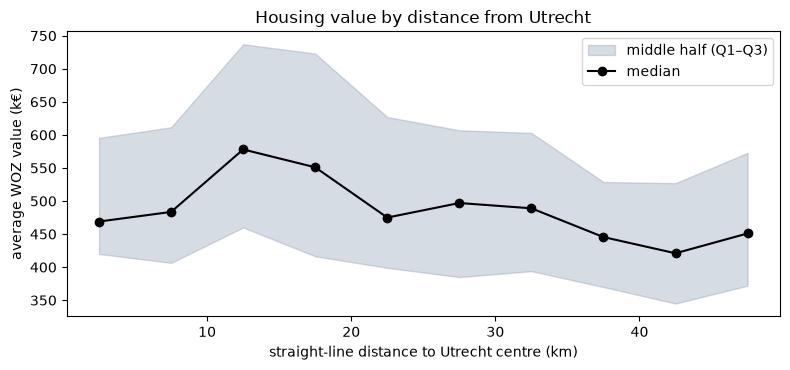

Spearman rank correlation within 50 km: -0.17  (n = 4454)


In [8]:
x = [b.left + 2.5 for b in by_band.index]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.fill_between(x, by_band["q1"], by_band["q3"], color="#7a8ba3", alpha=0.3, label="middle half (Q1–Q3)")
ax.plot(x, by_band["median_woz"], marker="o", color="black", label="median")
ax.set_xlabel(f"straight-line distance to {ANCHOR} centre (km)")
ax.set_ylabel("average WOZ value (k€)")
ax.set_title(f"Housing value by distance from {ANCHOR}")
ax.legend(); plt.tight_layout(); plt.show()

rho = near["dist_to_city_km"].corr(near["avg_woz_value_k_eur"], method="spearman")
print(f"Spearman rank correlation within 50 km: {rho:.2f}  (n = {len(near)})")

**Does value fall with distance? steadily, or not at all in some bands? how wide is the middle half compared with the change in the median? would a single correlation number have told me that?**

**My reading:** My starting assumption was "the further from the city, the cheaper", and the
data only partly agrees. Utrecht itself (0-5 km) has a median of 469k, but the ring at 10-20 km
is the most expensive (550-578k). Only beyond about 35 km does the median drop clearly below
the city (421-451k). The Spearman correlation is -0.17, which on its own would make me think
there is hardly any relationship. The chart shows a hump instead, so one correlation number
would have hidden the most interesting part.

The bigger lesson is the spread: inside every band the middle half covers 150k to 280k, more
than the whole change in the median across 50 km. So at any distance there are both cheap and
expensive neighbourhoods, and a rule of thumb does not help a newcomer. That is the reason the
app has to let them filter individual neighbourhoods instead of showing one average.

One more thing I did not expect: the share of private rentals is highest in the city itself
(median 20%) and around 8-12% further out. The places with lower values also have fewer homes a
newcomer could actually rent, which is a real trade-off and should be part of the story.

## 4 · Does it change if I include the estimated values?

If the conclusion only holds with or without the estimates, it is not a conclusion.

In [9]:
all_near = d[d["dist_to_city_km"] <= 50].copy()
all_near["band"] = pd.cut(all_near["dist_to_city_km"], bins=range(0, 55, 5), right=False)
sens = pd.DataFrame({
    "measured only": near.groupby("band", observed=True)["avg_woz_value_k_eur"].median(),
    "incl. estimated": all_near.groupby("band", observed=True)["avg_woz_value_k_eur"].median(),
    "share estimated": all_near.groupby("band", observed=True)["woz_estimated"].mean().mul(100),
}).round(1)
sens

,measured only,incl. estimated,share estimated
band,,,
"[0, 5)",469.0,476.5,4.6
"[5, 10)",483.5,497.0,15.6
"[10, 15)",578.0,576.0,14.5
"[15, 20)",551.0,551.0,9.6
"[20, 25)",475.0,484.0,10.9
"[25, 30)",497.0,498.0,16.6
"[30, 35)",489.0,485.0,14.5
"[35, 40)",445.5,448.0,17.1
"[40, 45)",421.0,418.0,14.5


**My reading:** Including the estimated values moves the band medians by at most 13.5k (5-10 km
band) and the shape of the curve stays the same, so the hump is not something my imputation
created.

## 5 · What this data does NOT let me conclude

* **Rent.** WOZ is a valuation of homes, not what a tenant pays. Lower WOZ suggests lower housing costs,
  it does not tell anyone what the rent will be.
* **Availability.** Nothing here says a home is free to rent today. A high private-rental share means
  those homes exist, not that one is on offer.
* **A single home.** These are neighbourhood averages. A cheap neighbourhood can contain expensive homes
  and the other way round.
* **Travel time.** Distance is a straight line, not a train or bike route. 20 km on an intercity line can be
  quicker than 8 km without one.
* **Cause.** The pattern by distance (a hump, not a steady fall) is a description, not an
  explanation; age of the homes, type of homes and local demand all change with distance too.
* **Corporation-owned is not social housing.** CBS only recorded who owns the home, not the
  rent, so "private rental share" is the best I have, not a precise measure of what a
  newcomer can get.
* **Per neighbourhood, not per home.** All band medians count each neighbourhood once.
  Section 2 shows this pushes values up by about 13% nationally, so the levels in the chart
  are a bit too high; the shape is what I rely on.

In [10]:
summary = {
    "median WOZ, per neighbourhood (k€)": round(woz.median(), 1),
    "median WOZ, per home (k€)": round(weighted_median(woz, w), 1),
    "Spearman distance vs WOZ (<=50 km)": round(rho, 2),
    "neighbourhoods within 50 km of " + ANCHOR: len(all_near),
}
pd.Series(summary).to_frame("value")

,value
"median WOZ, per neighbourhood (k€)",422.00
"median WOZ, per home (k€)",374.00
Spearman distance vs WOZ (<=50 km),-0.17
neighbourhoods within 50 km of Utrecht,5230.00
